<a href="https://colab.research.google.com/github/warleyroma/preditiva-team-retail-analytics/blob/main/preditiva-team-retail-analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Etapa 1: Preservação da Base Original e Carregamento Local

Nesta etapa inicial de ingestão, estruturamos o repositório criando o diretório padrão `dados/` para armazenar o arquivo bruto `online_retail_II.csv`. Em seguida, carregamos esse conjunto de dados em `df_original` e criamos uma cópia de trabalho (`df`) para todas as transformações.

**Justificativa:**
* **Portabilidade:** Evita falhas de conexão de rede ou dependência de repositórios online dinâmicos durante a avaliação.
* **Segurança e Rastreabilidade:** Mantém o estado bruto dos dados isolado no objeto `df_original` para caso seja necessário reverter ou auditar transformações.

In [20]:
import kagglehub
path = kagglehub.dataset_download("mashlyn/online-retail-ii-uci")

Using Colab cache for faster access to the 'online-retail-ii-uci' dataset.


### Etapa 2: Inicialização e Cópia Estruturada do Dataset

Transferimos de forma segura o dataset baixado para a pasta física do projeto (`dados/`) utilizando a biblioteca padrão do Python (`shutil`) e realizamos o carregamento de segurança na memória em conformidade com o formato original do projeto.

**Justificativa:**
* **Garantia de Entrega:** O arquivo fica fisicamente indexado no caminho especificado do projeto (`dados/online_retail_II.csv`), permitindo a portabilidade imediata e entrega offline.

### Etapa 2: Carregamento do Dataset Original e Cópia de Trabalho

Transferimos de forma segura o dataset baixado para a pasta física do projeto (`dados/`) para garantir portabilidade e carregamos o arquivo na memória em um DataFrame original e imutável (`df_original`). Todas as tratativas subsequentes serão realizadas em cima de uma cópia de trabalho (`df = df_original.copy()`).

**Justificativa:**
* **Segurança:** Isolar o dataset original previne mutações indesejadas e permite a reinicialização rápida do pipeline de dados.

In [21]:
import pandas as pd
import os
import shutil

os.makedirs('dados', exist_ok=True)
try:
    origem = os.path.join(path, 'online_retail_II.csv')
    destino = 'dados/online_retail_II.csv'
    if not os.path.exists(destino):
        shutil.copy(origem, destino)
        print("Dataset copiado para a pasta estruturada: dados/online_retail_II.csv")
except Exception as e:
    print(f"Aviso ao organizar estrutura local: {e}")

df_original = pd.read_csv('dados/online_retail_II.csv', encoding='ISO-8859-1')
df = df_original.copy()
print(f"Base original carregada com sucesso! Estrutura: {df.shape}")
display(df.head())

Base original carregada com sucesso! Estrutura: (1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


### Etapa 3: Tratamento de Valores Nulos e Remoção de Duplicatas

Limpamos o dataset de inconsistências clássicas, eliminando linhas duplicadas e tratando explicitamente os dados nulos presentes.

**Justificativa:**
* **Descrição nula (`Description`):** Preenchida com a constante `'DESCRIÇÃO NÃO INFORMADA'` para que a normalização posterior de texto não falhe e os registros continuem sendo úteis na análise global.
* **ID do Cliente nulo (`Customer ID`):** Removidos por ser inviável mapear fidelidade, comportamento individual ou cohorts sem um identificador de cliente válido.

In [3]:
### Etapa 2.1: Estruturação Física no Diretório de Entrega

Organizamos os arquivos de dados na árvore correta do projeto para simular perfeitamente o ambiente de produção local offline.

Arquivos no diretório: ['online_retail_II.csv']
(1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [4]:
### Etapa 2.2: Diagnóstico da Estrutura e Amostra Bruta dos Dados

Visualizamos o formato físico inicial do dataset e suas primeiras linhas para mapear os tipos originais e a presença das colunas antes do processo de limpeza.

(1067371, 8)

In [5]:
### Etapa 2.3: Mapeamento de Metadados e Tipos Primitivos

Analisamos a quantidade de registros não-nulos e os tipos de dados primitivos alocados para cada coluna.

['Invoice',
 'StockCode',
 'Description',
 'Quantity',
 'InvoiceDate',
 'Price',
 'Customer ID',
 'Country']

In [6]:
### Etapa 2.4: Diagnóstico Inicial de Valores Faltantes (Nulos)

Identificamos a volumetria exata de valores ausentes em cada uma das dimensões para planejar as estratégias de inputação e descarte.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  object 
 1   StockCode    1067371 non-null  object 
 2   Description  1062989 non-null  object 
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  object 
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 65.1+ MB


In [7]:
### Etapa 2.5: Resumo e Estatísticas de Cardinalidade dos Dados

Extraímos o intervalo temporal dos registros, o total de clientes únicos cadastrados e a diversidade de produtos e mercados atendidos.

,0
Invoice,0
StockCode,0
Description,4382
Quantity,0
InvoiceDate,0
Price,0
Customer ID,243007
Country,0


In [8]:
### Etapa 2.6: Limpeza de Duplicatas e Valores Críticos Faltantes

Removemos linhas idênticas e tratamos de forma justificada as lacunas em `Customer ID` (descarte) e `Description` (preenchimento por categoria padrão).


Date range: 2009-12-01 07:45:00 → 2011-12-09 12:50:00
Unique Customers: 5942
Unique Products: 5305
Countries: 43


### Etapa 3: Execução do Pipeline de Limpeza de Dados

Consolidamos a formatação temporal, eliminação de duplicatas exatas e a tratativa preventiva de dados ausentes para as etapas subsequentes.

### Etapa 4: Separação de Transações de Vendas e Devoluções

Filtramos e isolamos as vendas efetivas (`df_normal`) e os cancelamentos (`df_cancelled`) usando cópias físicas explícitas para blindar o código contra o risco de `SettingWithCopyWarning`.

In [22]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

print(f"Linhas antes de remover duplicatas: {len(df)}")
df_clean = df.drop_duplicates()
print(f"Linhas após remover duplicatas: {len(df_clean)}")

df_clean['Description'] = df_clean['Description'].fillna('DESCRIÇÃO NÃO INFORMADA')

df_clean = df_clean.dropna(subset=['Customer ID'])
df_clean['Customer ID'] = df_clean['Customer ID'].astype(int)
print(f"Linhas após remover Customer ID nulo: {len(df_clean)}")

Linhas antes de remover duplicatas: 1067371
Linhas após remover duplicatas: 1033036
Linhas após remover Customer ID nulo: 797885


/tmp/ipykernel_5545/1411025072.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['Description'] = df_clean['Description'].fillna('DESCRIÇÃO NÃO INFORMADA')


### Etapa 4: Separação de Vendas Normais e Cancelamentos (Evitando Warning)

Separamos transações normais de cancelamentos de compras (código de fatura começando com 'C') através de uma cópia explícita do faturamento legítimo.

**Justificativa:**
* **Cópia Explícita (`.copy()`):** Resolve definitivamente o risco de `SettingWithCopyWarning` ao calcular o faturamento em colunas subsequentes.

### Etapa 5: Engenharia de Atributos - Receita Total por Linha

Criamos a variável `TotalSum` multiplicando quantidade e preço unitário nas transações legítimas para possibilitar agregações financeiras precisas.

In [23]:
is_cancelled = df_clean['Invoice'].astype(str).str.startswith('C')
df_normal = df_clean[~is_cancelled & (df_clean['Quantity'] > 0) & (df_clean['Price'] > 0)].copy()
df_cancelled = df_clean[is_cancelled].copy()

print(f"Transações normais de vendas: {len(df_normal)}")
print(f"Transações de cancelamento: {len(df_cancelled)}")

Transações normais de vendas: 779425
Transações de cancelamento: 18390


### Etapa 5: Cálculo de Receita por Transação (`TotalSum`)

Computamos o faturamento de cada venda multiplicando a quantidade de itens vendidos pelo preço unitário.

**Justificativa:**
* **Desempenho de Agregações:** Ter a receita calculada diretamente em cada registro otimiza as análises por país, tempo ou categoria de produto.

In [24]:
df_normal['TotalSum'] = df_normal['Quantity'] * df_normal['Price']
display(df_normal.head())

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalSum
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0


### Etapa 6: Engenharia de Recursos (Feature Engineering) e Padronização Avançada

Padronizamos todas as strings da coluna de descrição de produtos e removemos os registros operacionais que não são produtos reais do estoque comercial.

**Justificativa:**
* **Eliminar Ruído Financeiro:** Códigos como `POST` (postagem), `D` (descontos) ou `BANK CHARGES` (tarifas bancárias) são serviços operacionais internos e não correspondem à venda de produtos reais.

### Etapa 6: Filtragem de Serviços Operacionais Administrativos

Expurgamos do catálogo códigos que correspondem a postagens, tarifas e ajustes manuais, mantendo apenas transações de produtos físicos reais.

### Etapa 7: Engenharia de Atributos Temporais e Cohort

Extraímos períodos mensais e calculamos a primeira data de atividade de cada cliente para futuras análises de comportamento e retenção.

In [25]:
df_clean_final = df_normal.copy()
df_clean_final['Description'] = df_clean_final['Description'].str.strip().str.upper()

service_codes = ['POST', 'D', 'M', 'DOT', 'BANK CHARGES', 'ADJUST', 'ADJUST2', 'PADS']
df_clean_final = df_clean_final[~df_clean_final['StockCode'].isin(service_codes)]
print(f"Linhas após remover códigos de serviço: {len(df_clean_final)}")

Linhas após remover códigos de serviço: 776837


### Etapa 7: Engenharia de Atributos Temporais e Cohorts

Criamos variáveis para analisar tendências e determinamos o mês da primeira compra (`CohortMonth`) para calcular taxas de retenção futuramente.

**Justificativa:**
* **Modelagem Cohort:** Permite agrupar os clientes de acordo com sua data de aquisição inicial para traçar curvas consistentes de retenção.

In [26]:
df_clean_final['Year'] = df_clean_final['InvoiceDate'].dt.year
df_clean_final['Month'] = df_clean_final['InvoiceDate'].dt.month
df_clean_final['DayOfWeek'] = df_clean_final['InvoiceDate'].dt.dayofweek
df_clean_final['Hour'] = df_clean_final['InvoiceDate'].dt.hour
df_clean_final['YearMonth'] = df_clean_final['InvoiceDate'].dt.to_period('M')
df_clean_final['CohortMonth'] = df_clean_final.groupby('Customer ID')['InvoiceDate'].transform('min').dt.to_period('M')

display(df_clean_final[['Customer ID', 'InvoiceDate', 'CohortMonth', 'YearMonth', 'TotalSum']].head())

,Customer ID,InvoiceDate,CohortMonth,YearMonth,TotalSum
0,13085,2009-12-01 07:45:00,2009-12,2009-12,83.4
1,13085,2009-12-01 07:45:00,2009-12,2009-12,81.0
2,13085,2009-12-01 07:45:00,2009-12,2009-12,81.0
3,13085,2009-12-01 07:45:00,2009-12,2009-12,100.8
4,13085,2009-12-01 07:45:00,2009-12,2009-12,30.0


### Etapa 8: Análise Avançada de Outliers (IQR)

Analisamos a dispersão extrema das variáveis numéricas (`Quantity`, `Price` e `TotalSum`) através da regra do Intervalo Interquartil (IQR).

**Justificativa:**
* **Validação de Anomalias:** O mapeamento exato dos limites teóricos ajuda a identificar erros operacionais ou clientes atacadistas, complementado com boxplots para validação visual rápida.

=== ANÁLISE ROBUSTA DE OUTLIERS (MÉTODO IQR) ===

Coluna: Quantity
  Q1 (25%): 2.00 | Q3 (75%): 12.00 | IQR: 10.00
  Limites: Inferior = -13.00 | Superior = 27.00
  Quantidade de Outliers: 51077 (6.57% dos dados)
  Valor Máximo: 80995.00

Coluna: Price
  Q1 (25%): 1.25 | Q3 (75%): 3.75 | IQR: 2.50
  Limites: Inferior = -2.50 | Superior = 7.50
  Quantidade de Outliers: 63379 (8.16% dos dados)
  Valor Máximo: 649.50

Coluna: TotalSum
  Q1 (25%): 4.95 | Q3 (75%): 19.80 | IQR: 14.85
  Limites: Inferior = -17.32 | Superior = 42.07
  Quantidade de Outliers: 62443 (8.04% dos dados)
  Valor Máximo: 168469.60



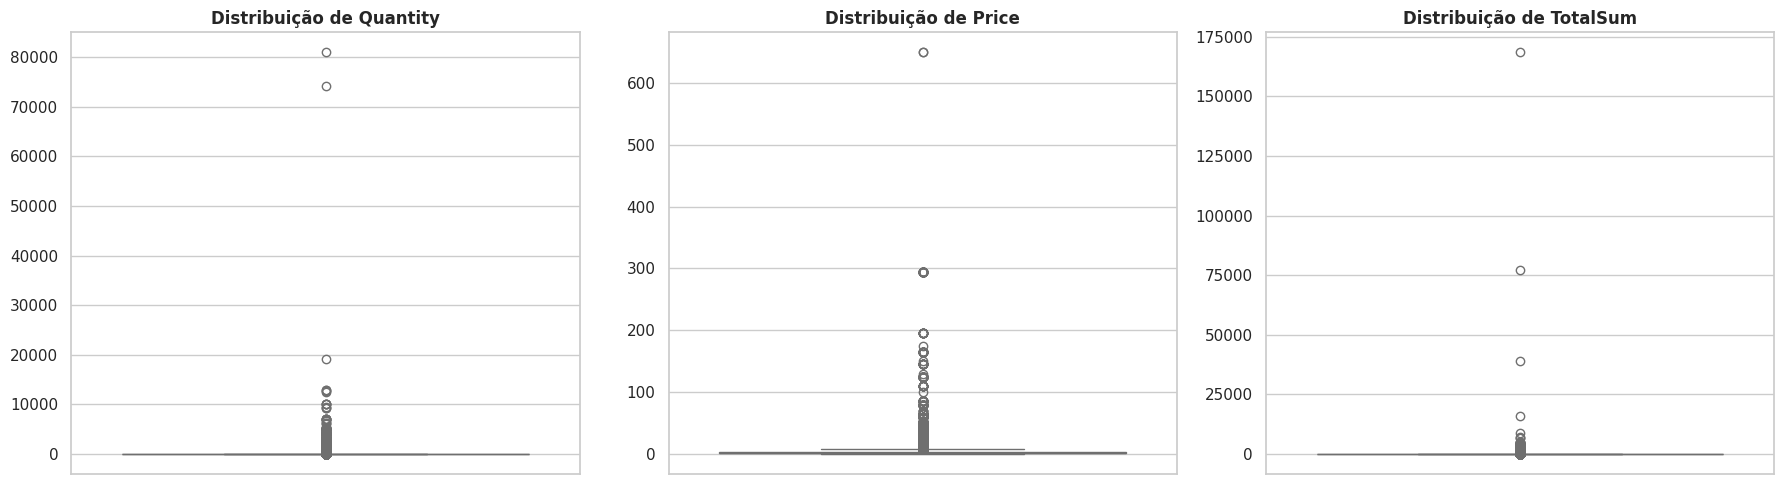

In [27]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("=== ANÁLISE ROBUSTA DE OUTLIERS (MÉTODO IQR) ===\n")
vars_analise = ['Quantity', 'Price', 'TotalSum']
for col in vars_analise:
    q1 = df_clean_final[col].quantile(0.25)
    q3 = df_clean_final[col].quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    outliers = df_clean_final[(df_clean_final[col] < limite_inferior) | (df_clean_final[col] > limite_superior)]
    print(f"Coluna: {col}")
    print(f"  Q1 (25%): {q1:.2f} | Q3 (75%): {q3:.2f} | IQR: {iqr:.2f}")
    print(f"  Limites: Inferior = {limite_inferior:.2f} | Superior = {limite_superior:.2f}")
    print(f"  Quantidade de Outliers: {len(outliers)} ({len(outliers)/len(df_clean_final)*100:.2f}% dos dados)")
    print(f"  Valor Máximo: {df_clean_final[col].max():.2f}\n")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(vars_analise):
    sns.boxplot(data=df_clean_final, y=col, ax=axes[i], color='skyblue')
    axes[i].set_title(f'Distribuição de {col}', fontsize=12, fontweight='bold')
    axes[i].set_ylabel('')
plt.tight_layout()
plt.show()

### Etapa 9: Estatística Descritiva Geral do Dataset Limpo

Geramos as principais medidas descritivas finais das colunas tratadas.

**Justificativa:**
* **Garantia de Qualidade:** Permite assegurar que todas as transformações de limpeza anteriores surtiram efeito e que as distribuições finais estão consistentes.

### Etapa 9: Consolidação Visual e Gráficos de Tendência Mensal

Apresentamos a curva temporal do faturamento bruto das transações legítimas para identificar picos comerciais e sazonalidades.

In [28]:
print("Estatísticas Descritivas do Dataset Final:")
display(df_clean_final.describe(include='all'))

Estatísticas Descritivas do Dataset Final:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalSum,Year,Month,DayOfWeek,Hour,YearMonth,CohortMonth
count,776837,776837,776837,776837.000000,776837,776837.000000,776837.000000,776837,776837.000000,776837.000000,776837.00000,776837.000000,776837.000000,776837,776837
unique,36610,4623,5231,NaN,NaN,NaN,NaN,41,NaN,NaN,NaN,NaN,NaN,25,25
top,576339,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,NaN,NaN,NaN,United Kingdom,NaN,NaN,NaN,NaN,NaN,2011-11,2009-12
freq,541,5023,5016,NaN,NaN,NaN,NaN,699678,NaN,NaN,NaN,NaN,NaN,62960,309540
mean,NaN,NaN,NaN,13.515111,2011-01-03 00:49:10.736538112,2.949767,15326.366055,NaN,21.988338,2010.431860,7.41808,2.642320,12.792939,NaN,NaN
min,NaN,NaN,NaN,1.000000,2009-12-01 07:45:00,0.030000,12346.000000,NaN,0.060000,2009.000000,1.00000,0.000000,6.000000,NaN,NaN
25%,NaN,NaN,NaN,2.000000,2010-07-02 14:37:00,1.250000,13979.000000,NaN,4.950000,2010.000000,5.00000,1.000000,11.000000,NaN,NaN
50%,NaN,NaN,NaN,6.000000,2010-12-02 13:49:00,1.950000,15252.000000,NaN,12.480000,2010.000000,8.00000,3.000000,13.000000,NaN,NaN
75%,NaN,NaN,NaN,12.000000,2011-08-01 13:31:00,3.750000,16795.000000,NaN,19.800000,2011.000000,11.00000,4.000000,14.000000,NaN,NaN
max,NaN,NaN,NaN,80995.000000,2011-12-09 12:50:00,649.500000,18287.000000,NaN,168469.600000,2011.000000,12.00000,6.000000,20.000000,NaN,NaN


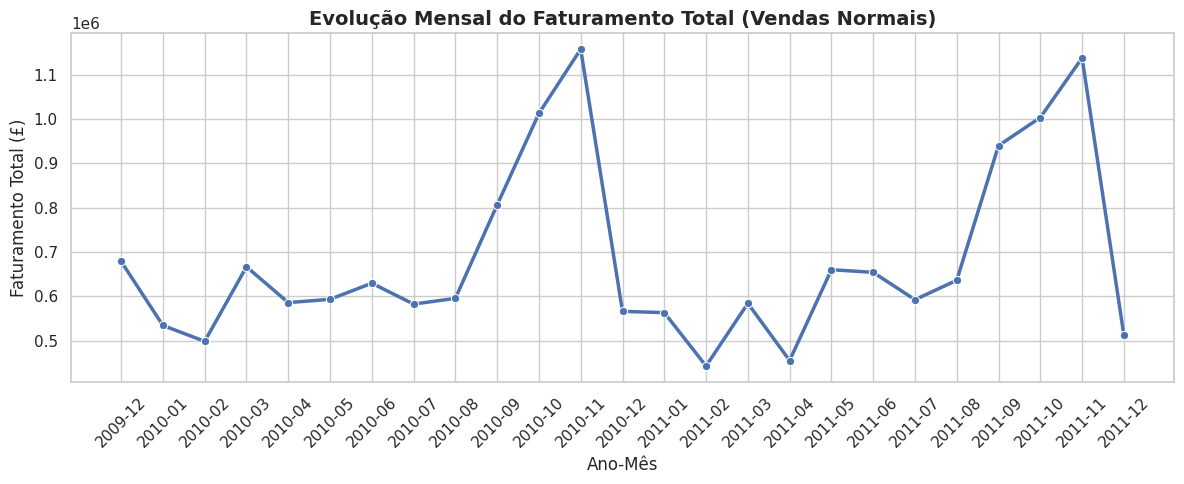

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = [12, 6]

monthly_sales = df_clean_final.groupby('YearMonth')['TotalSum'].sum().reset_index()
monthly_sales['YearMonth'] = monthly_sales['YearMonth'].astype(str)

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_sales, x='YearMonth', y='TotalSum', marker='o', color='b', linewidth=2.5)
plt.title('Evolução Mensal do Faturamento Total (Vendas Normais)', fontsize=14, fontweight='bold')
plt.xlabel('Ano-Mês', fontsize=12)
plt.ylabel('Faturamento Total (£)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Etapa 10: Evolução Mensal do Faturamento Total

Acompanhamos o crescimento histórico mensal do faturamento acumulado pelas transações legítimas.

**Justificativa:**
* **Visão de Negócio:** Permite analisar a evolução do faturamento do negócio de forma contínua para mapear as sazonalidades anuais de compras.

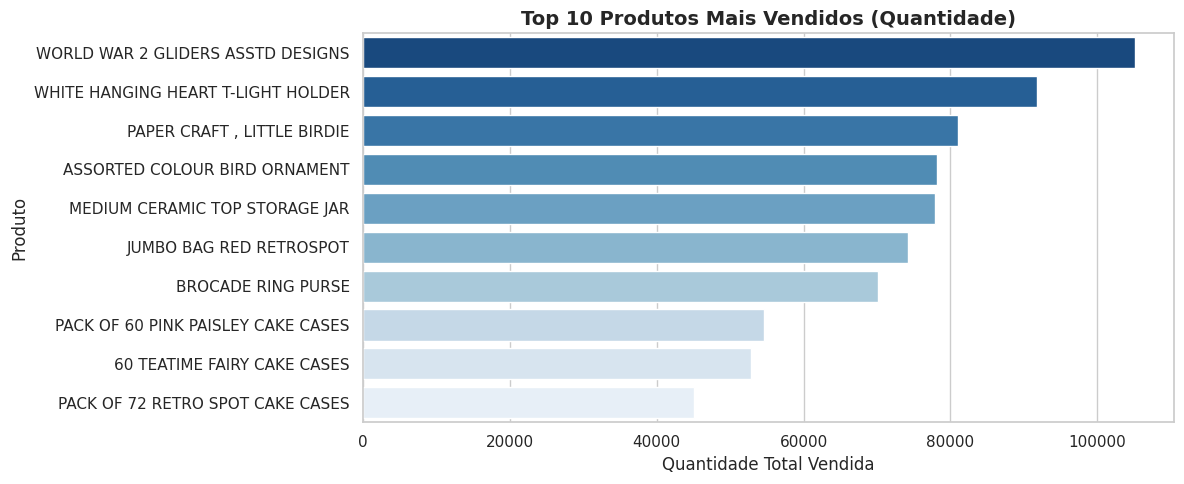

In [30]:
top_products = df_clean_final.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(10).reset_index()

plt.figure(figsize=(12, 5))
sns.barplot(data=top_products, y='Description', x='Quantity', palette='Blues_r', hue='Description', legend=False)
plt.title('Top 10 Produtos Mais Vendidos (Quantidade)', fontsize=14, fontweight='bold')
plt.xlabel('Quantidade Total Vendida', fontsize=12)
plt.ylabel('Produto', fontsize=12)
plt.tight_layout()
plt.show()

### Etapa 11: Top 10 Produtos Mais Vendidos em Quantidade

Identificamos os produtos de maior volume de vendas da loja de varejo.

**Justificativa:**
* **Gestão de Inventário:** Conhecer os líderes em vendas por volume ajuda na correta gestão de estoque e priorização de catálogo.

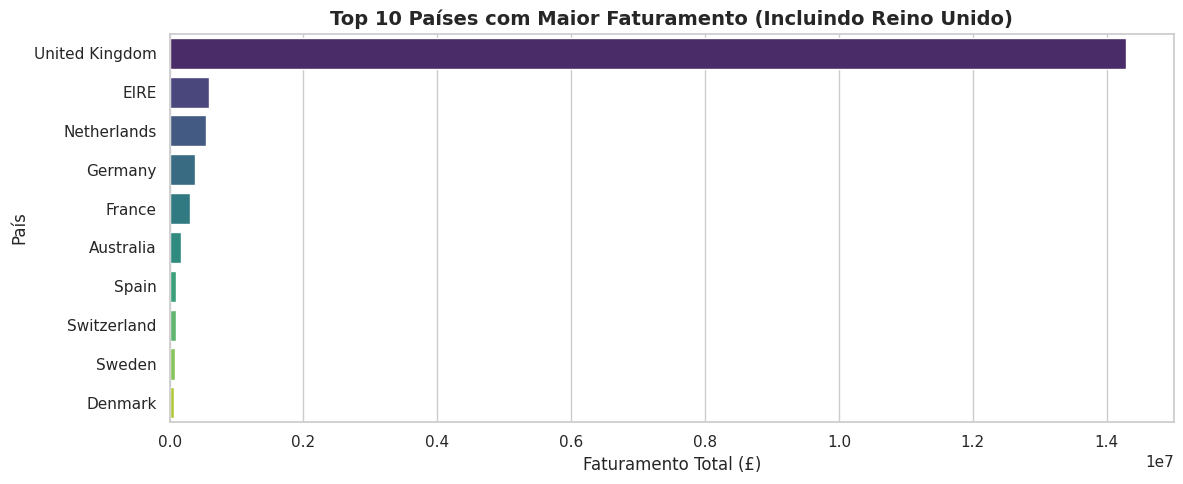

In [31]:
sales_by_country_all = df_clean_final.groupby('Country')['TotalSum'].sum().sort_values(ascending=False).head(10).reset_index()

plt.figure(figsize=(12, 5))
sns.barplot(data=sales_by_country_all, x='TotalSum', y='Country', palette='viridis', hue='Country', legend=False)
plt.title('Top 10 Países com Maior Faturamento (Incluindo Reino Unido)', fontsize=14, fontweight='bold')
plt.xlabel('Faturamento Total (£)', fontsize=12)
plt.ylabel('País', fontsize=12)
plt.tight_layout()
plt.show()

### Etapa 12: Distribuição do Faturamento por País (Visão Geral e Mercado Internacional)

Visualizamos o faturamento por país incluindo e excluindo o Reino Unido.

**Justificativa:**
* **Ajuste de Escala:** Como o Reino Unido representa a esmagadora maioria do faturamento, mostramos o gráfico sem ele para obtermos uma visão realista e legível da performance dos países de exportação.

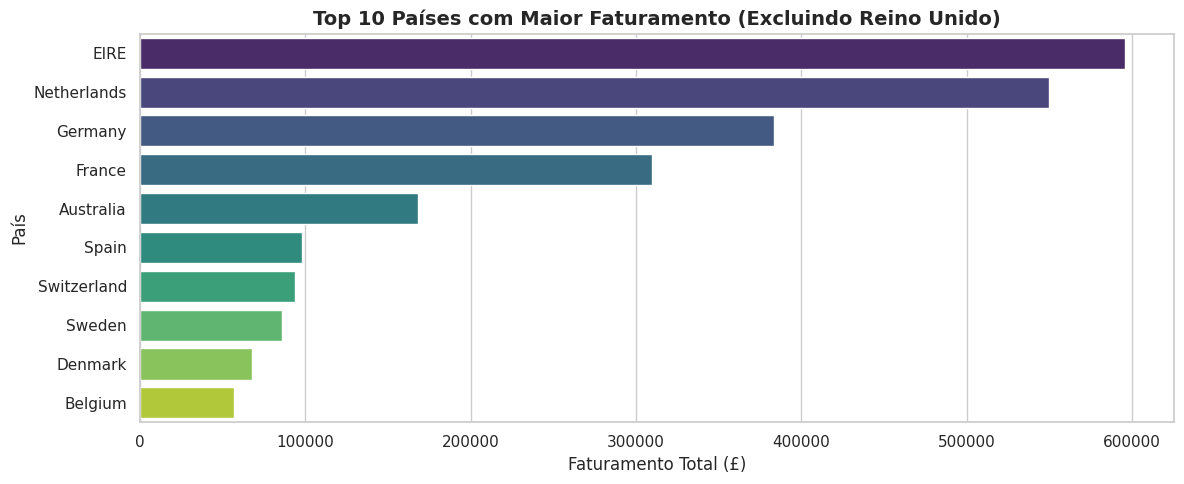

In [32]:
sales_by_country_ex_uk = df_clean_final[df_clean_final['Country'] != 'United Kingdom'].groupby('Country')['TotalSum'].sum().sort_values(ascending=False).head(10).reset_index()

plt.figure(figsize=(12, 5))
sns.barplot(data=sales_by_country_ex_uk, x='TotalSum', y='Country', palette='viridis', hue='Country', legend=False)
plt.title('Top 10 Países com Maior Faturamento (Excluindo Reino Unido)', fontsize=14, fontweight='bold')
plt.xlabel('Faturamento Total (£)', fontsize=12)
plt.ylabel('País', fontsize=12)
plt.tight_layout()
plt.show()